# MIE1624 - Assignment 1

In [1]:
%pip install pandas numpy matplotlib scipy scikit-learn


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
df = pd.read_csv("clean_stackoverflow_data.csv")
df.head()

,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,YearsCode,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,25.0,Master's degree,Employed,"Caring for dependents (children, elderly, etc.)",8,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,14,...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don't trust AI's answers,"Troubleshooting, profiling, debugging",61256,10.0
1,34.0,Associate degree,Employed,NaN,2,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,10,...,NaN,NaN,NaN,NaN,NaN,NaN,When I don't trust AI's answers;When I want to...,All skills. AI is a flop.,104413,9.0
2,39.0,Bachelor's degree,Employed,None of the above,4,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Videos (no...,5,...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don't trust AI's answers;When I want to...,NaN,36197,6.0
3,41.0,Professional degree,Employed,Engaged in paid work (20-29 hours per week);Tr...,22,"Yes, I am not new to coding but am learning ne...",Books / Physical media;Technical documentation...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Blogs or p...,30,...,NaN,NaN,NaN,NaN,NaN,NaN,When I want to learn best practices;When I wan...,"Innovation, system design",72000,6.0
4,27.0,Bachelor's degree,Employed,"Caring for dependents (children, elderly, etc....",9,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",Technical documentation (is generated for/by t...,15,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70000,8.0


# Question 1: Exploratory Data Analysis

This section explores the main characteristics of the Stack Overflow survey dataset and examines job satisfaction, salary, job title, and age.

In [4]:
# Number of Rows and Columns in the Dataset
df.shape

(20407, 168)

In [5]:
# General Overview of the Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20407 entries, 0 to 20406
Columns: 168 entries, Age to JobSat
dtypes: float64(48), int64(3), object(117)
memory usage: 26.2+ MB


In [6]:
# Create a a list called eda_columns that stores the names of the 4 columns we care about for Question 1
eda_columns = ['DevType', 'ConvertedCompYearly', 'JobSat', 'Age']

df[eda_columns].head()

,DevType,ConvertedCompYearly,JobSat,Age
0,"Developer, mobile",61256,10.0,25.0
1,"Developer, back-end",104413,9.0,34.0
2,"Developer, back-end",36197,6.0,39.0
3,"Architect, software or solutions",72000,6.0,41.0
4,Data engineer,70000,8.0,27.0


In [7]:
# Basic Statistical Summary for EDA
df[['Age', 'ConvertedCompYearly', 'JobSat']].describe()

,Age,ConvertedCompYearly,JobSat
count,20397.000000,2.040700e+04,16958.000000
mean,36.788792,1.021167e+05,7.192063
std,11.147327,3.399749e+05,1.967919
min,1.000000,1.020000e+02,0.000000
25%,29.000000,4.227300e+04,6.000000
50%,35.000000,7.773000e+04,8.000000
75%,43.000000,1.239930e+05,8.000000
max,151.000000,3.355272e+07,60.000000


The descriptive statistics reveal several potential anomalies. Annual salary is highly right-skewed, with a maximum value of over $33 million compared with a median of approximately $77,730. The maximum reported age of 151 and the job satisfaction value of 60 also appear unrealistic and should be examined before visualization and further analysis.

## Figure 1

In [8]:
# Check the unique job satisfaction values
sorted(df['JobSat'].dropna().unique())

[np.float64(0.0),
 np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0),
 np.float64(6.0),
 np.float64(7.0),
 np.float64(8.0),
 np.float64(9.0),
 np.float64(10.0),
 np.float64(60.0)]

In [9]:
# Keep only valid job satisfaction scores between 0 and 10
jobsat_data = df[df['JobSat'].between(0, 10)].copy()

In [10]:
# Calculate average job satisfaction and number of responses by job title
jobsat_summary = (
    jobsat_data
    .groupby('DevType')['JobSat']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
)

jobsat_summary

,mean,count
DevType,,
Retired,10.000000,1
"Senior executive (C-suite, VP, etc.)",8.112426,169
"Founder, technology or otherwise",8.011905,84
Product manager,7.680000,25
Applied scientist,7.621212,66
"Developer, game or graphics",7.593333,150
Financial analyst or engineer,7.500000,14
"Architect, software or solutions",7.477740,1168
Project manager,7.463415,41


In [11]:
# Keep job titles with at least 20 valid responses
jobsat_plot_data = jobsat_summary[jobsat_summary['count'] >= 20]

jobsat_plot_data

,mean,count
DevType,,
"Senior executive (C-suite, VP, etc.)",8.112426,169
"Founder, technology or otherwise",8.011905,84
Product manager,7.680000,25
Applied scientist,7.621212,66
"Developer, game or graphics",7.593333,150
"Architect, software or solutions",7.477740,1168
Project manager,7.463415,41
Data scientist,7.441026,195
Cybersecurity or InfoSec professional,7.378788,66


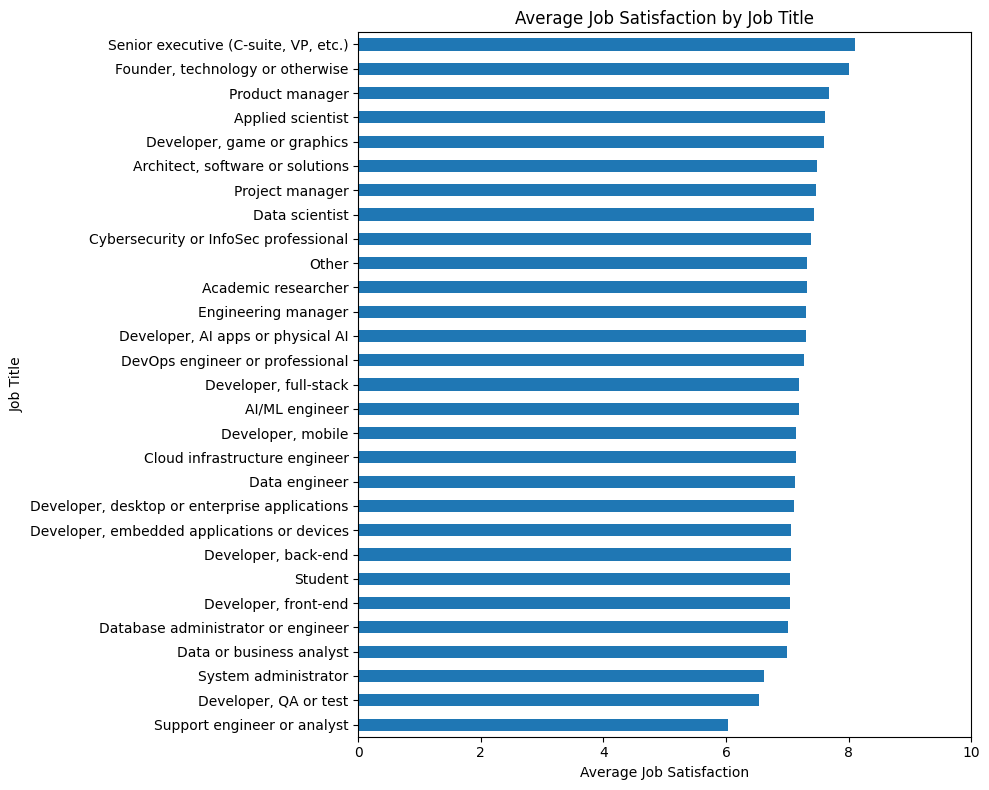

In [12]:
# Figure 1: Average Job Satisfaction by Job Title
plt.figure(figsize=(10, 8))

jobsat_plot_data['mean'].sort_values().plot(kind='barh')

plt.title('Average Job Satisfaction by Job Title')
plt.xlabel('Average Job Satisfaction')
plt.ylabel('Job Title')
plt.xlim(0, 10)

plt.tight_layout()
plt.show()

Job titles with fewer than 20 valid job-satisfaction responses were excluded because averages based on very small groups may be unstable and misleading.

**Figure 1 Interpretation:**  
Among job titles with at least 20 valid responses, senior executives reported the highest average job satisfaction, while support engineers or analysts reported the lowest, indicating moderate variation in satisfaction across job roles.

## Figure 2

In [13]:
# Calculate mean salary and number of responses by job title
salary_summary = (
    df.groupby('DevType')['ConvertedCompYearly']
      .agg(['mean', 'count'])
      .sort_values('mean', ascending=False)
)

salary_summary

,mean,count
DevType,,
Financial analyst or engineer,501248.000000,46
Retired,222534.000000,2
"Senior executive (C-suite, VP, etc.)",215633.142336,274
Engineering manager,178747.668182,660
Cybersecurity or InfoSec professional,153592.088757,169
"Founder, technology or otherwise",138610.632000,125
Product manager,129927.535354,99
Cloud infrastructure engineer,129036.801724,232
Applied scientist,123069.441379,145


In [14]:
# Keep job titles with at least 20 salary responses
salary_plot_data = salary_summary[salary_summary['count'] >= 20]

salary_plot_data

,mean,count
DevType,,
Financial analyst or engineer,501248.000000,46
"Senior executive (C-suite, VP, etc.)",215633.142336,274
Engineering manager,178747.668182,660
Cybersecurity or InfoSec professional,153592.088757,169
"Founder, technology or otherwise",138610.632000,125
Product manager,129927.535354,99
Cloud infrastructure engineer,129036.801724,232
Applied scientist,123069.441379,145
"Architect, software or solutions",119646.273826,1406


The average salary of a financial analyst or engineer is far above almost every other role. There is one respondent in that category with a salary of about $18.4 million, while the median salary for that same role is only about $87,249. That one extreme value is massively inflating the mean.

In [15]:
# Inspect salary distribution for potential outliers
df['ConvertedCompYearly'].describe()

count    2.040700e+04
mean     1.021167e+05
std      3.399749e+05
min      1.020000e+02
25%      4.227300e+04
50%      7.773000e+04
75%      1.239930e+05
max      3.355272e+07
Name: ConvertedCompYearly, dtype: float64

In [16]:
# Calculate IQR-based salary outlier threshold
Q1 = df['ConvertedCompYearly'].quantile(0.25)
Q3 = df['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 42273.0
Q3: 123993.0
IQR: 81720.0
Lower bound: -80307.0
Upper bound: 246573.0


In [17]:
# Count salary outliers
salary_outliers = df[df['ConvertedCompYearly'] > upper_bound]

print("Number of salary outliers:", len(salary_outliers))
print("Percentage of dataset:", len(salary_outliers) / len(df) * 100)

Number of salary outliers: 907
Percentage of dataset: 4.444553339540354


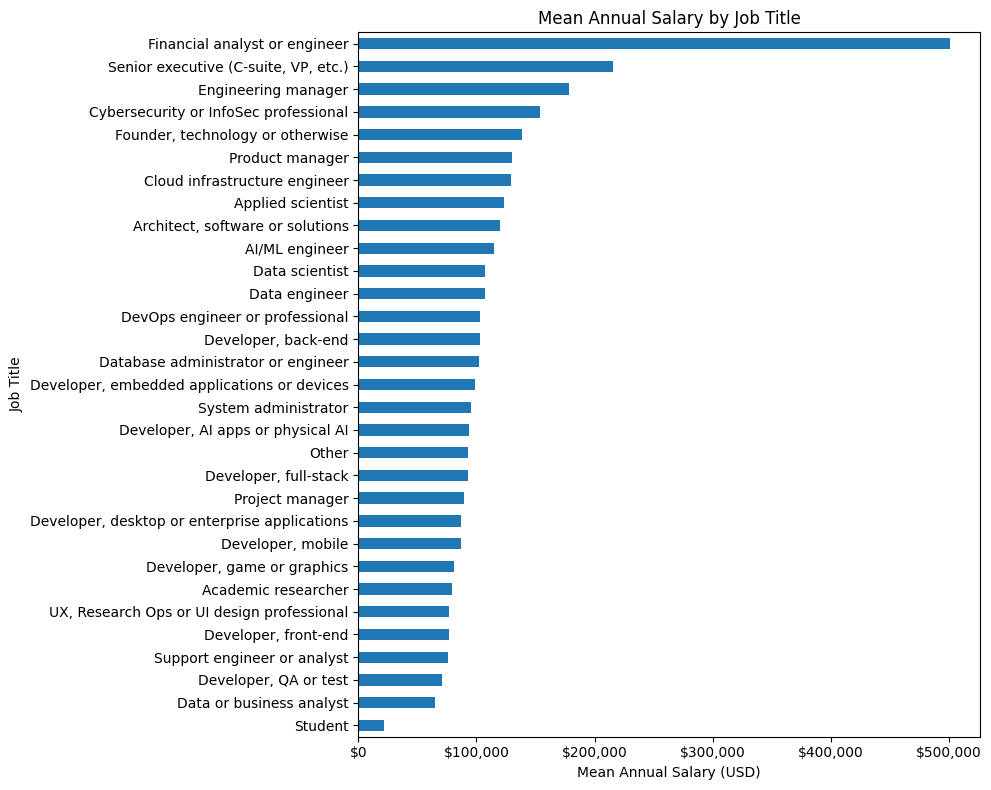

In [18]:
# Figure 2: Mean Salary by Job Title
plt.figure(figsize=(10, 8))

salary_plot_data['mean'].sort_values().plot(kind='barh')

plt.title('Mean Annual Salary by Job Title')
plt.xlabel('Mean Annual Salary (USD)')
plt.ylabel('Job Title')

from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.show()

Job titles with fewer than 20 salary responses were excluded to reduce instability from very small groups. Salary outliers were retained because the IQR rule identified 907 high-salary observations, representing about 4.44% of the dataset, and automatically removing all of them could exclude legitimate high-income respondents.

**Figure 2 Interpretation:**  
Financial analysts or engineers have an unusually high mean salary compared with all other job titles, suggesting that extreme salary values within this group may be substantially inflating the average.

## Figure 3

In [19]:
# Inspect age distribution
df['Age'].describe()

count    20397.000000
mean        36.788792
std         11.147327
min          1.000000
25%         29.000000
50%         35.000000
75%         43.000000
max        151.000000
Name: Age, dtype: float64

In [20]:
# Check unusually high ages
df[df['Age'] > 100][['Age', 'ConvertedCompYearly']]

,Age,ConvertedCompYearly
6395,151.0,67289
10295,126.0,2672890


There are two clearly unusual ages above 100:
- age 126 with salary about $2.67M
- age 151 with salary about $67k

In [21]:
# Create plotting data with plausible ages only
age_salary_plot_data = df[df['Age'] <= 100].copy()

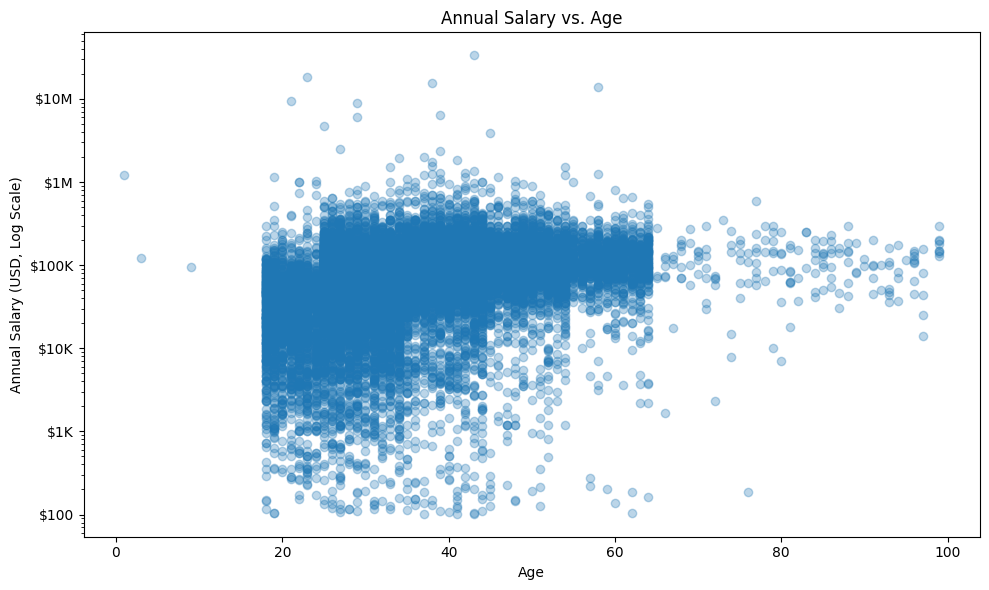

In [22]:
# Figure 3: Annual Salary vs. Age
plt.figure(figsize=(10, 6))

plt.scatter(
    age_salary_plot_data['Age'],
    age_salary_plot_data['ConvertedCompYearly'],
    alpha=0.3
)

plt.title('Annual Salary vs. Age')
plt.xlabel('Age')
plt.ylabel('Annual Salary (USD, Log Scale)')

plt.yscale('log')

from matplotlib.ticker import FuncFormatter

def salary_formatter(y, _):
    if y >= 1_000_000:
        return f'${y/1_000_000:.0f}M'
    elif y >= 1_000:
        return f'${y/1_000:.0f}K'
    else:
        return f'${y:,.0f}'

plt.gca().yaxis.set_major_formatter(FuncFormatter(salary_formatter))

plt.tight_layout()
plt.show()

Respondents with ages above 100 were excluded from this visualization as implausible age values, while salary observations were retained and displayed on a logarithmic scale to reduce distortion from extreme salaries.

**Figure 3 Interpretation:**  
Annual salary generally increases from younger ages into middle age, but the relationship is highly variable and includes several extreme high-salary outliers.

# Question 2: Hybrid vs. Remote Salary Comparison

This section compares the salaries of hybrid and remote workers using descriptive statistics, hypothesis testing, bootstrapping, confidence intervals, and median-based analysis.

## Question 2a: Descriptive Statistics + Outlier Decision

In [23]:
# Check the available job-mode categories
df['RemoteWork'].value_counts(dropna=False)

RemoteWork
Hybrid                         7803
Remote                         6934
In-person                      2993
Your choice (very flexible)    2677
Name: count, dtype: int64

In [24]:
# Create salary groups for hybrid and remote workers
hybrid_salary = df.loc[
    df['RemoteWork'] == 'Hybrid',
    'ConvertedCompYearly'
].dropna()

remote_salary = df.loc[
    df['RemoteWork'] == 'Remote',
    'ConvertedCompYearly'
].dropna()

print("Hybrid sample size:", len(hybrid_salary))
print("Remote sample size:", len(remote_salary))

Hybrid sample size: 7803
Remote sample size: 6934


In [25]:
# Calculate IQR outlier thresholds separately for each group
def iqr_bounds(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return q1, q3, iqr, lower, upper

hybrid_bounds = iqr_bounds(hybrid_salary)
remote_bounds = iqr_bounds(remote_salary)

print("Hybrid:")
print("Q1:", hybrid_bounds[0])
print("Q3:", hybrid_bounds[1])
print("IQR:", hybrid_bounds[2])
print("Lower bound:", hybrid_bounds[3])
print("Upper bound:", hybrid_bounds[4])

print("\nRemote:")
print("Q1:", remote_bounds[0])
print("Q3:", remote_bounds[1])
print("IQR:", remote_bounds[2])
print("Lower bound:", remote_bounds[3])
print("Upper bound:", remote_bounds[4])

Hybrid:
Q1: 47566.0
Q3: 116015.0
IQR: 68449.0
Lower bound: -55107.5
Upper bound: 218688.5

Remote:
Q1: 47650.0
Q3: 150000.0
IQR: 102350.0
Lower bound: -105875.0
Upper bound: 303525.0


In [26]:
# Count salary outliers in each group
hybrid_outliers = hybrid_salary[hybrid_salary > hybrid_bounds[4]]
remote_outliers = remote_salary[remote_salary > remote_bounds[4]]

print("Hybrid outliers:", len(hybrid_outliers))
print("Hybrid outlier percentage:", len(hybrid_outliers) / len(hybrid_salary) * 100)

print("Remote outliers:", len(remote_outliers))
print("Remote outlier percentage:", len(remote_outliers) / len(remote_salary) * 100)

Hybrid outliers: 403
Hybrid outlier percentage: 5.164680251185441
Remote outliers: 204
Remote outlier percentage: 2.9420248053071822


In [27]:
# Remove IQR-based high salary outliers from each group
hybrid_salary_clean = hybrid_salary[
    hybrid_salary <= hybrid_bounds[4]
]

remote_salary_clean = remote_salary[
    remote_salary <= remote_bounds[4]
]

print("Hybrid observations before removal:", len(hybrid_salary))
print("Hybrid observations after removal:", len(hybrid_salary_clean))

print("Remote observations before removal:", len(remote_salary))
print("Remote observations after removal:", len(remote_salary_clean))

Hybrid observations before removal: 7803
Hybrid observations after removal: 7400
Remote observations before removal: 6934
Remote observations after removal: 6730


In [28]:
# Descriptive statistics after outlier removal
salary_stats_clean = pd.DataFrame({
    'Hybrid': hybrid_salary_clean.describe(),
    'Remote': remote_salary_clean.describe()
})

salary_stats_clean

,Hybrid,Remote
count,7400.000000,6730.000000
mean,79921.160000,98709.002526
std,47866.970827,68111.233345
min,104.000000,102.000000
25%,46406.000000,46406.000000
50%,74878.000000,87735.000000
75%,108913.000000,145000.000000
max,218000.000000,303000.000000


**Outlier Rationale:**   
Salary outliers were identified separately within the hybrid and remote groups using the 1.5 × IQR rule. This identified 403 hybrid observations (5.16%) above $218,688.50 and 204 remote observations (2.94%) above $303,525. These high-end observations were removed because extreme salary values can disproportionately influence the group means, variances, and subsequent mean-based statistical tests. No lower outliers were removed because the calculated lower bounds were negative while all salaries were positive.

After removing high-end IQR outliers, remote workers had a higher mean annual salary (about $98,709) than hybrid workers (about $79,921), with the same pattern also appearing in the medians.

## Question 2b: Two-sample t-test

In [29]:
# Manual two-sample t-test calculation

# Sample sizes
n_hybrid = len(hybrid_salary_clean)
n_remote = len(remote_salary_clean)

# Sample means
mean_hybrid = hybrid_salary_clean.mean()
mean_remote = remote_salary_clean.mean()

# Sample variances
var_hybrid = hybrid_salary_clean.var(ddof=1)
var_remote = remote_salary_clean.var(ddof=1)

# Pooled variance
pooled_variance = (
    ((n_hybrid - 1) * var_hybrid) +
    ((n_remote - 1) * var_remote)
) / (n_hybrid + n_remote - 2)

# Pooled standard deviation
pooled_std = np.sqrt(pooled_variance)

# Standard error of the difference in means
standard_error = pooled_std * np.sqrt(
    (1 / n_hybrid) + (1 / n_remote)
)

# t-statistic
t_stat_manual = (
    mean_hybrid - mean_remote
) / standard_error

# Degrees of freedom
df_t = n_hybrid + n_remote - 2

print("Hybrid mean:", mean_hybrid)
print("Remote mean:", mean_remote)
print("Hybrid variance:", var_hybrid)
print("Remote variance:", var_remote)
print("Pooled standard deviation:", pooled_std)
print("Standard error:", standard_error)
print("Manual t-statistic:", t_stat_manual)
print("Degrees of freedom:", df_t)

Hybrid mean: 79921.16
Remote mean: 98709.00252600297
Hybrid variance: 2291246896.132797
Remote variance: 4639140107.742154
Pooled standard deviation: 58391.1018843364
Standard error: 983.5452826688557
Manual t-statistic: -19.10216322223827
Degrees of freedom: 14128


In [30]:
# Manual two-sided p-value
p_value_manual = 2 * stats.t.sf(
    abs(t_stat_manual),
    df=df_t
)

print("Manual p-value:", p_value_manual)

Manual p-value: 2.4872668180921185e-80


In [31]:
# Built-in two-sample t-test
t_stat_builtin, p_value_builtin = stats.ttest_ind(
    hybrid_salary_clean,
    remote_salary_clean,
    equal_var=True
)

print("Built-in t-statistic:", t_stat_builtin)
print("Built-in p-value:", p_value_builtin)

Built-in t-statistic: -19.102163222238275
Built-in p-value: 2.487266818091977e-80


**Manual and Built-in Calculations Comparison:**  
Since the p-value is far below the 0.05 significance level, we reject the null hypothesis and conclude that the mean salaries of hybrid and remote workers are significantly different. The negative t-statistic indicates that the hybrid mean salary is lower than the remote mean salary. In addition, the manual pooled t-test and the built-in equal-variance t-test produced nearly identical results, confirming that the manual calculation was implemented correctly.

Since the hybrid and remote workers have noticeably different standard deviations *(found in 2a)*, we need to check the equal-variance assumption using Levene’s test, then comparing the pooled t-test with Welch’s t-test, which does not assume equal variances.

In [32]:
# Check equality of variances using Levene's test
levene_stat, levene_p = stats.levene(
    hybrid_salary_clean,
    remote_salary_clean
)

print("Levene's test statistic:", levene_stat)
print("Levene's test p-value:", levene_p)

Levene's test statistic: 781.6567723008085
Levene's test p-value: 1.8242359345575097e-167


In [33]:
# Welch's two-sample t-test
t_stat_welch, p_value_welch = stats.ttest_ind(
    hybrid_salary_clean,
    remote_salary_clean,
    equal_var=False
)

print("Welch's t-statistic:", t_stat_welch)
print("Welch's p-value:", p_value_welch)

Welch's t-statistic: -18.797710043251712
Welch's p-value: 1.0387552166272957e-77


**Levene's and Welch's Tests:**  
Levene’s test produced a p-value far below 0.05, indicating that the equal-variance assumption is violated. Therefore, Welch’s two-sample t-test is more appropriate. Welch’s test also produced an extremely small p-value, so the conclusion remains the same: the mean salary of remote workers is significantly different from, and higher than, that of hybrid workers. Welch’s t-test gave a slightly different t-statistic because it does not assume equal variances, but it led to the same statistical conclusion.

## Question 2c: Bootstrap Hybrid and Remote Salary Means


In [34]:
# Bootstrap hybrid and remote salary means

np.random.seed(42)

n_bootstrap = 10000

hybrid_boot_means = np.empty(n_bootstrap)
remote_boot_means = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    hybrid_sample = np.random.choice(
        hybrid_salary_clean,
        size=len(hybrid_salary_clean),
        replace=True
    )

    remote_sample = np.random.choice(
        remote_salary_clean,
        size=len(remote_salary_clean),
        replace=True
    )

    hybrid_boot_means[i] = hybrid_sample.mean()
    remote_boot_means[i] = remote_sample.mean()

print("Hybrid bootstrap mean:", hybrid_boot_means.mean())
print("Remote bootstrap mean:", remote_boot_means.mean())

Hybrid bootstrap mean: 79917.0273135135
Remote bootstrap mean: 98716.57067404159


Bbootstrap means are:
- Hybrid: about $79,917
- Remote: about $98,717

These are extremely close to the original cleaned means from 2a:
- Hybrid original mean: about $79,921
- Remote original mean: about $98,709

### Figure 2c.1

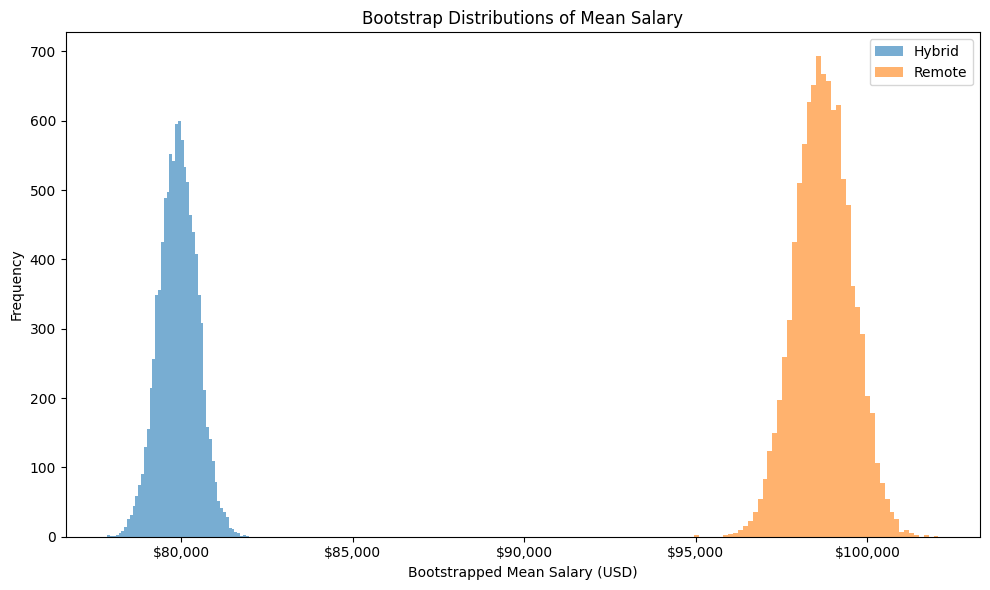

In [35]:
# Figure 2c.1: Bootstrap distributions of mean salary

plt.figure(figsize=(10, 6))

plt.hist(
    hybrid_boot_means,
    bins=50,
    alpha=0.6,
    label='Hybrid'
)

plt.hist(
    remote_boot_means,
    bins=50,
    alpha=0.6,
    label='Remote'
)

plt.title('Bootstrap Distributions of Mean Salary')
plt.xlabel('Bootstrapped Mean Salary (USD)')
plt.ylabel('Frequency')
plt.legend()

from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:,.0f}')
)

plt.tight_layout()
plt.show()

**Figure 2c.1 Interpretation:**  
The bootstrap distributions of the mean salaries are well separated, with the remote-worker distribution centered noticeably higher than the hybrid-worker distribution, indicating a consistent difference in average salary between the two groups.

### Figure 2c.2

In [36]:
# Calculate bootstrap differences in means
boot_mean_diff = remote_boot_means - hybrid_boot_means

print("Average bootstrap difference in means:", boot_mean_diff.mean())

Average bootstrap difference in means: 18799.543360528092


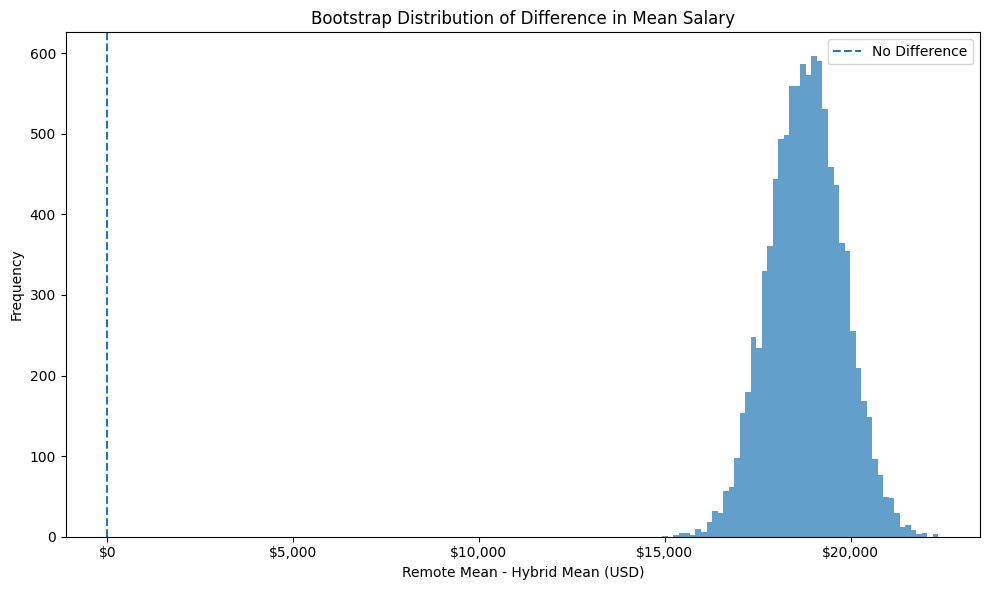

In [37]:
# Figure 2c.2: Bootstrap distribution of difference in means
plt.figure(figsize=(10, 6))

plt.hist(
    boot_mean_diff,
    bins=50,
    alpha=0.7
)

plt.axvline(
    0,
    linestyle='--',
    label='No Difference'
)

plt.title('Bootstrap Distribution of Difference in Mean Salary')
plt.xlabel('Remote Mean - Hybrid Mean (USD)')
plt.ylabel('Frequency')
plt.legend()

from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:,.0f}')
)

plt.tight_layout()
plt.show()

**Figure 2c.2 Interpretation:**  
The bootstrap distributions of the mean salaries are well separated, with the remote-worker distribution centered noticeably higher than the hybrid-worker distribution, indicating a consistent difference in average salary between the two groups.

### Figure 2c.3

In [38]:
# Standardize the bootstrap distribution of the difference in means
standardized_diff = (
    boot_mean_diff - boot_mean_diff.mean()
) / boot_mean_diff.std(ddof=1)

print("Mean of standardized distribution:", standardized_diff.mean())
print("Standard deviation:", standardized_diff.std(ddof=1))

Mean of standardized distribution: -1.0331291377951857e-15
Standard deviation: 1.0


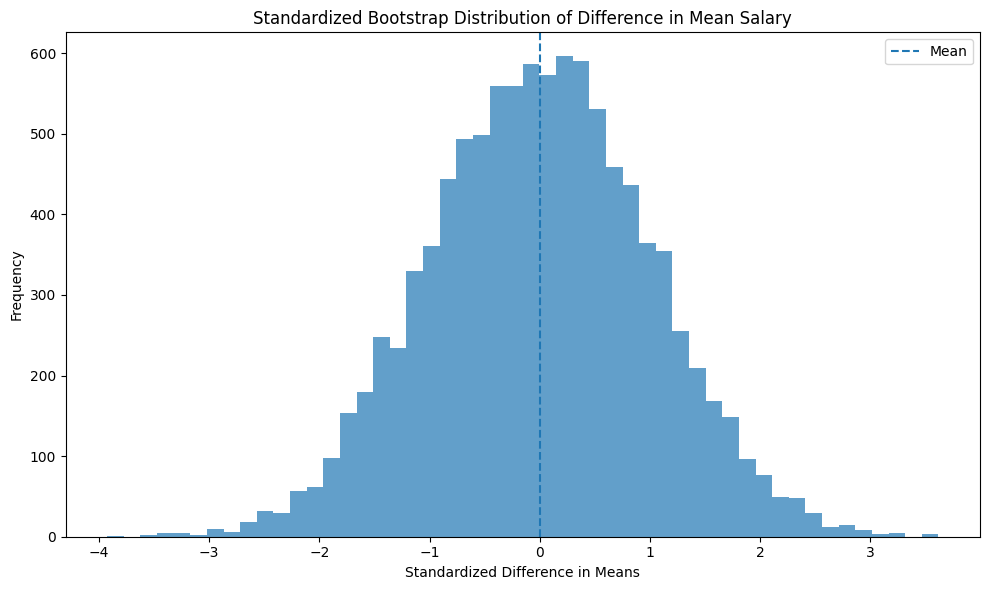

In [39]:
# Figure 2c.3: Standardized bootstrap distribution of difference in means
plt.figure(figsize=(10, 6))

plt.hist(
    standardized_diff,
    bins=50,
    alpha=0.7
)

plt.axvline(
    0,
    linestyle='--',
    label='Mean'
)

plt.title('Standardized Bootstrap Distribution of Difference in Mean Salary')
plt.xlabel('Standardized Difference in Means')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()

**Figure 2c.3 Interpretation:**  
The standardized bootstrap distribution is approximately bell-shaped and centered near zero, showing that the bootstrapped differences in mean salary are distributed fairly symmetrically around their average difference.

## Question 2d: Perform a Two-sample t-test Using the Bootstrapped Data and Compare it with 2b

In [40]:
# Observed difference in mean salaries
observed_diff = remote_salary_clean.mean() - hybrid_salary_clean.mean()

# Bootstrap estimate of the standard error
bootstrap_se = boot_mean_diff.std(ddof=1)

# Bootstrap-based t-statistic
t_stat_boot = observed_diff / bootstrap_se

print("Observed difference in means:", observed_diff)
print("Bootstrap standard error:", bootstrap_se)
print("Bootstrap-based t-statistic:", t_stat_boot)

Observed difference in means: 18787.84252600296
Bootstrap standard error: 984.4783692893931
Bootstrap-based t-statistic: 19.08405823031361


In [41]:
# Two-sided bootstrap-based p-value
p_value_boot = 2 * stats.norm.sf(abs(t_stat_boot))

print("Bootstrap-based p-value:", p_value_boot)

alpha = 0.05

if p_value_boot < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Bootstrap-based p-value: 3.425959007586013e-81
Reject the null hypothesis.


**2d and 2b Results Comparison:**  
The bootstrap-based test produced a t-statistic of approximately 19.09 and an extremely small p-value, well below the 0.05 significance level. Therefore, the null hypothesis is rejected, indicating a statistically significant difference in mean salary between remote and hybrid workers. This agrees with the results from Question 2b, where both the pooled and Welch’s t-tests also found a highly significant difference. The sign differs because the bootstrap calculation used Remote − Hybrid, while the earlier manual t-test used Hybrid − Remote.

## Question 2e: 95% Confidence Intervals for the Difference in Mean Salary

In [42]:
# Difference in mean salaries
mean_diff = remote_salary_clean.mean() - hybrid_salary_clean.mean()

# Pooled standard deviation from Question 2b
pooled_std = np.sqrt(
    (
        (len(hybrid_salary_clean) - 1) * hybrid_salary_clean.var(ddof=1)
        +
        (len(remote_salary_clean) - 1) * remote_salary_clean.var(ddof=1)
    )
    /
    (len(hybrid_salary_clean) + len(remote_salary_clean) - 2)
)

# Standard error of the difference
se_diff = pooled_std * np.sqrt(
    1 / len(hybrid_salary_clean)
    +
    1 / len(remote_salary_clean)
)

# Degrees of freedom
df_ci = len(hybrid_salary_clean) + len(remote_salary_clean) - 2

# Critical t-value for 95% confidence
t_critical = stats.t.ppf(0.975, df_ci)

# Formula-based 95% confidence interval
ci_lower_formula = mean_diff - t_critical * se_diff
ci_upper_formula = mean_diff + t_critical * se_diff

print("Mean difference:", mean_diff)
print("Formula-based 95% CI:",
      (ci_lower_formula, ci_upper_formula))

Mean difference: 18787.84252600296
Formula-based 95% CI: (np.float64(16859.964031112697), np.float64(20715.721020893227))


In [43]:
# Bootstrap 95% confidence interval
ci_lower_boot = np.percentile(boot_mean_diff, 2.5)
ci_upper_boot = np.percentile(boot_mean_diff, 97.5)

print("Bootstrap 95% CI:",
      (ci_lower_boot, ci_upper_boot))

Bootstrap 95% CI: (np.float64(16898.521234257663), np.float64(20719.55907216577))


Results:
- **Formula-based 95% CI**: $16,860 to $20,716
- **Bootstrap 95% CI**: $16,899 to $20,720  
This means both methods give essentially the same conclusion.

**2e Interpretation:**  
The formula-based 95% confidence interval for the difference in mean salary was approximately $16,860 to $20,716, while the bootstrap 95% confidence interval was approximately $16,899 to $20,720. The two intervals are very similar and both lie entirely above zero, indicating that remote workers have a statistically higher mean salary than hybrid workers. The close agreement between the two methods suggests that the result is robust to the choice of confidence-interval approach.

## Question 2f: Mood’s Median Test and the Bootstrap Comparison of Median Differences

In [44]:
# 2f. Mood's median test

mood_stat, mood_p, grand_median, contingency_table = stats.median_test(
    hybrid_salary_clean,
    remote_salary_clean
)

print("Mood's test statistic:", mood_stat)
print("Mood's p-value:", mood_p)
print("Grand median:", grand_median)
print("Contingency table:")
print(contingency_table)

Mood's test statistic: 123.215744950002
Mood's p-value: 1.2508119991823697e-28
Grand median: 80080.0
Contingency table:
[[3370 3695]
 [4030 3035]]


In [45]:
# Bootstrap median differences

np.random.seed(42)

n_bootstrap = 10000

hybrid_boot_medians = np.empty(n_bootstrap)
remote_boot_medians = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    hybrid_sample = np.random.choice(
        hybrid_salary_clean,
        size=len(hybrid_salary_clean),
        replace=True
    )

    remote_sample = np.random.choice(
        remote_salary_clean,
        size=len(remote_salary_clean),
        replace=True
    )

    hybrid_boot_medians[i] = np.median(hybrid_sample)
    remote_boot_medians[i] = np.median(remote_sample)

In [46]:
# Remote - Hybrid median difference
boot_median_diff = remote_boot_medians - hybrid_boot_medians

print("Average bootstrap median difference:", boot_median_diff.mean())

Average bootstrap median difference: 13455.05185


In [47]:
# Two-sided bootstrap p-value for difference in medians

count_lower = np.sum(boot_median_diff <= 0)
count_upper = np.sum(boot_median_diff >= 0)

bootstrap_median_p = 2 * (
    min(count_lower, count_upper) + 1
) / (n_bootstrap + 1)

print("Bootstrap median p-value:", bootstrap_median_p)

Bootstrap median p-value: 0.00019998000199980003


**2f Interpretation:**   
Mood’s median test produced an extremely small p-value (approximately 1.25X10^{-28}), indicating a statistically significant difference between the median salaries of hybrid and remote workers. The bootstrap analysis also produced a very small two-sided p-value (approximately 0.0002), with remote workers having a bootstrap median salary about $13,455 higher on average. Although the numerical p-values are not close in magnitude, both methods lead to the same conclusion that the median salaries differ significantly.

# Question 3

This section examines how education level relates to salary among respondents from the United States and Canada using descriptive statistics, ANOVA, and bootstrap analysis.

In [48]:
# Check country values
df['Country'].value_counts().head(20)

Country
United States of America    4679
Germany                     1910
Great Britain               1323
India                        938
France                       862
Canada                       789
Ukraine                      560
Netherlands                  539
Brazil                       523
Australia                    486
Spain                        481
Italy                        479
Poland                       439
Sweden                       415
Switzerland                  373
Czech Republic               262
Austria                      248
Denmark                      203
Portugal                     188
Norway                       175
Name: count, dtype: int64

In [49]:
# Check education level categories
df['EdLevel'].value_counts(dropna=False)

EdLevel
Bachelor's degree                                         9086
Master's degree                                           5946
Some college/university study without earning a degree    2342
Professional degree                                       1183
Secondary school                                           922
Associate degree                                           679
Other                                                      166
Primary/elementary school                                   83
Name: count, dtype: int64

In [50]:
# Keep only participants from the US and Canada
north_america = df[
    df['Country'].isin(['United States of America', 'Canada'])
].copy()

In [51]:
# Keep only the three education groups required for Question 3
education_data = north_america[
    north_america['EdLevel'].isin([
        "Bachelor's degree",
        "Master's degree",
        "Professional degree"
    ])
].copy()

In [52]:
education_data['EdLevel'].value_counts()

EdLevel
Bachelor's degree      2978
Master's degree        1084
Professional degree     301
Name: count, dtype: int64

## Question 3a: Descriptive Statistics

In [53]:
# Descriptive statistics by education level
education_stats = (
    education_data
    .groupby('EdLevel')['ConvertedCompYearly']
    .describe()
)

education_stats

,count,mean,std,min,25%,50%,75%,max
EdLevel,,,,,,,,
Bachelor's degree,2978.0,160987.604433,113742.423728,126.0,100000.0,140000.0,190000.0,1950000.0
Master's degree,1084.0,182220.476937,161910.830185,125.0,110750.0,157000.0,215000.0,3900000.0
Professional degree,301.0,197700.960133,194866.381460,185.0,108000.0,160000.0,217000.0,2346000.0


In [54]:
# Calculate IQR outlier bounds for each education group

education_groups = [
    "Bachelor's degree",
    "Master's degree",
    "Professional degree"
]

for level in education_groups:
    salaries = education_data.loc[
        education_data['EdLevel'] == level,
        'ConvertedCompYearly'
    ]

    q1 = salaries.quantile(0.25)
    q3 = salaries.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = salaries[salaries > upper_bound]

    print(level)
    print("Upper bound:", upper_bound)
    print("Number of high outliers:", len(outliers))
    print("Outlier percentage:", len(outliers) / len(salaries) * 100)
    print()

Bachelor's degree
Upper bound: 325000.0
Number of high outliers: 151
Outlier percentage: 5.070517125587642

Master's degree
Upper bound: 371375.0
Number of high outliers: 54
Outlier percentage: 4.981549815498155

Professional degree
Upper bound: 380500.0
Number of high outliers: 21
Outlier percentage: 6.976744186046512



In [55]:
# Remove high-end IQR outliers within each education group

cleaned_education_groups = []

for level in education_groups:
    group_data = education_data[
        education_data['EdLevel'] == level
    ].copy()

    q1 = group_data['ConvertedCompYearly'].quantile(0.25)
    q3 = group_data['ConvertedCompYearly'].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    group_data = group_data[
        group_data['ConvertedCompYearly'] <= upper_bound
    ]

    cleaned_education_groups.append(group_data)

education_data_clean = pd.concat(cleaned_education_groups)

In [56]:
# Descriptive statistics after outlier removal
education_stats_clean = (
    education_data_clean
    .groupby('EdLevel')['ConvertedCompYearly']
    .describe()
)

education_stats_clean

,count,mean,std,min,25%,50%,75%,max
EdLevel,,,,,,,,
Bachelor's degree,2827.0,142386.815352,61289.270671,126.0,100000.0,138000.0,180000.0,325000.0
Master's degree,1030.0,160073.015534,73511.933299,125.0,110000.0,150000.0,200000.0,370000.0
Professional degree,280.0,159507.103571,75089.863552,185.0,102106.5,155000.0,200000.0,375000.0


- Bachelor’s: n = 2,827, mean ≈ $142,387, median = $138,000
- Master’s: n = 1,030, mean ≈ $160,073, median = $150,000
- Professional degree: n = 280, mean ≈ $159,507, median = $155,000

**Outlier Rationale:**  
High-end salary outliers were identified separately within each education group using the 1.5 × IQR rule. This identified 151 Bachelor’s observations (5.07%), 54 Master’s observations (4.98%), and 21 Professional-degree observations (6.98%) above their respective upper bounds. These observations were removed because extreme salaries can disproportionately influence group means and ANOVA results.

**3a Interpretation:**  
After removing high-end IQR outliers, Bachelor’s degree holders had the lowest mean salary, while Master’s and Professional degree holders had similar, higher mean salaries.

## Question 3b: ANOVA

In [57]:
# Create cleaned salary groups for ANOVA
bachelors_salary = education_data_clean.loc[
    education_data_clean['EdLevel'] == "Bachelor's degree",
    'ConvertedCompYearly'
]

masters_salary = education_data_clean.loc[
    education_data_clean['EdLevel'] == "Master's degree",
    'ConvertedCompYearly'
]

professional_salary = education_data_clean.loc[
    education_data_clean['EdLevel'] == "Professional degree",
    'ConvertedCompYearly'
]

In [58]:
# One-way ANOVA
f_stat, anova_p = stats.f_oneway(
    bachelors_salary,
    masters_salary,
    professional_salary
)

print("ANOVA F-statistic:", f_stat)
print("ANOVA p-value:", anova_p)

ANOVA F-statistic: 32.17274765856014
ANOVA p-value: 1.3651427958387671e-14


**3b Interpretation:**    
The one-way ANOVA produced an F-statistic of approximately 32.17 and a p-value of 1.37X10^{-14}, which is far below the 0.05 significance level. Therefore, the null hypothesis is rejected, indicating that at least one of the three education groups has a significantly different mean salary.

## Question 3c: Bootstrapping

In [59]:
# Bootstrap mean salaries for the three education groups

np.random.seed(42)

n_bootstrap = 10000

bachelors_boot_means = np.empty(n_bootstrap)
masters_boot_means = np.empty(n_bootstrap)
professional_boot_means = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    bachelors_sample = np.random.choice(
        bachelors_salary,
        size=len(bachelors_salary),
        replace=True
    )

    masters_sample = np.random.choice(
        masters_salary,
        size=len(masters_salary),
        replace=True
    )

    professional_sample = np.random.choice(
        professional_salary,
        size=len(professional_salary),
        replace=True
    )

    bachelors_boot_means[i] = bachelors_sample.mean()
    masters_boot_means[i] = masters_sample.mean()
    professional_boot_means[i] = professional_sample.mean()

print("Bachelor's bootstrap mean:", bachelors_boot_means.mean())
print("Master's bootstrap mean:", masters_boot_means.mean())
print("Professional bootstrap mean:", professional_boot_means.mean())

Bachelor's bootstrap mean: 142383.7183492395
Master's bootstrap mean: 160096.02070650485
Professional bootstrap mean: 159503.72197392854


### Question 3c.1: Bootstrap Distributions of Mean Salary by Education Level

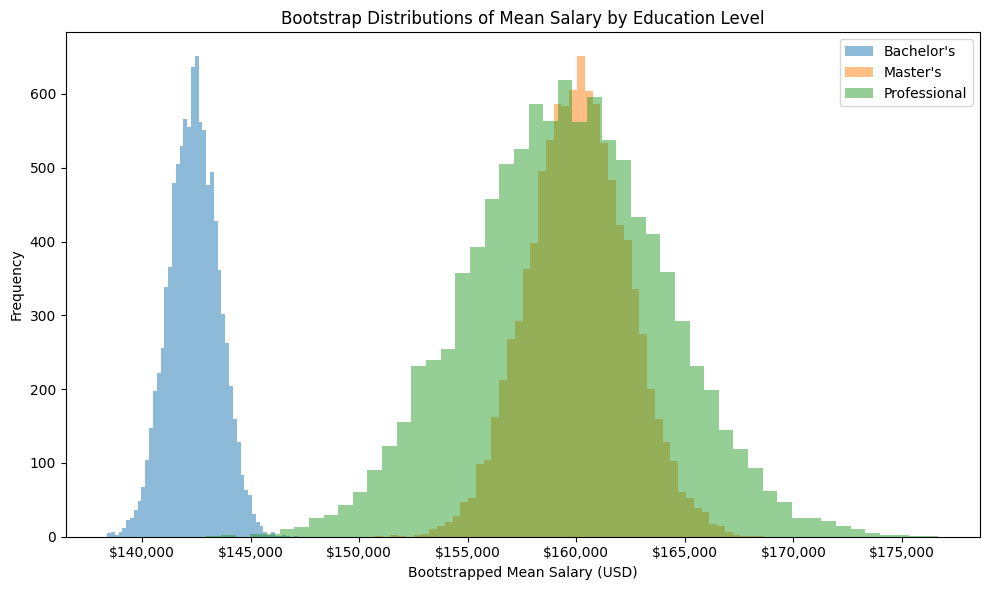

In [60]:
# Bootstrap distributions of mean salary by education level

plt.figure(figsize=(10, 6))

plt.hist(
    bachelors_boot_means,
    bins=50,
    alpha=0.5,
    label="Bachelor's"
)

plt.hist(
    masters_boot_means,
    bins=50,
    alpha=0.5,
    label="Master's"
)

plt.hist(
    professional_boot_means,
    bins=50,
    alpha=0.5,
    label="Professional"
)

plt.title('Bootstrap Distributions of Mean Salary by Education Level')
plt.xlabel('Bootstrapped Mean Salary (USD)')
plt.ylabel('Frequency')
plt.legend()

from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:,.0f}')
)

plt.tight_layout()
plt.show()

- Bachelor’s: ≈ $142,384
- Master’s: ≈ $160,096
- Professional: ≈ $159,504

### 3c.2: Pairwise Bootstrapping

In [61]:
# Pairwise bootstrap differences in means

diff_masters_bachelors = masters_boot_means - bachelors_boot_means
diff_professional_bachelors = professional_boot_means - bachelors_boot_means
diff_professional_masters = professional_boot_means - masters_boot_means

print("Master's - Bachelor's mean difference:", diff_masters_bachelors.mean())
print("Professional - Bachelor's mean difference:", diff_professional_bachelors.mean())
print("Professional - Master's mean difference:", diff_professional_masters.mean())

Master's - Bachelor's mean difference: 17712.302357265376
Professional - Bachelor's mean difference: 17120.003624689096
Professional - Master's mean difference: -592.2987325762832


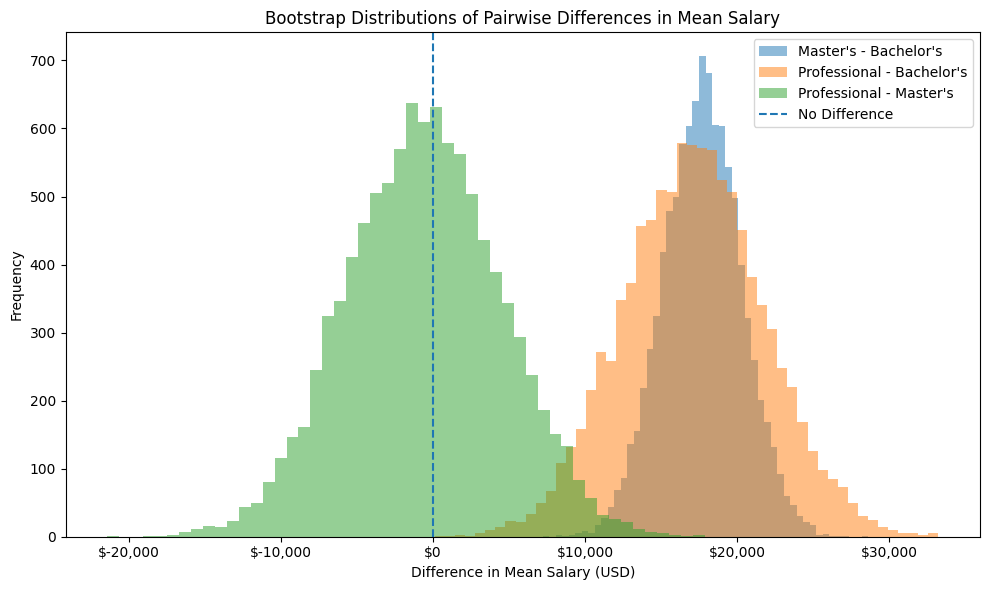

In [62]:
# Figure 3c.2: Pairwise bootstrap distributions of differences in mean salary

plt.figure(figsize=(10, 6))

plt.hist(
    diff_masters_bachelors,
    bins=50,
    alpha=0.5,
    label="Master's - Bachelor's"
)

plt.hist(
    diff_professional_bachelors,
    bins=50,
    alpha=0.5,
    label="Professional - Bachelor's"
)

plt.hist(
    diff_professional_masters,
    bins=50,
    alpha=0.5,
    label="Professional - Master's"
)

plt.axvline(0, linestyle='--', label='No Difference')

plt.title('Bootstrap Distributions of Pairwise Differences in Mean Salary')
plt.xlabel('Difference in Mean Salary (USD)')
plt.ylabel('Frequency')
plt.legend()

from matplotlib.ticker import FuncFormatter
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:,.0f}')
)

plt.tight_layout()
plt.show()

**3c.2 Interpretation:**  
The pairwise bootstrap distributions show clear positive differences for Master’s versus Bachelor’s and Professional versus Bachelor’s salaries, while the Professional versus Master’s distribution is centered near zero, suggesting little difference between those two groups.

### 3c.3: Standardized Pairwise Bootstrapping

In [63]:
# Standardize pairwise difference distributions

std_diff_masters_bachelors = (
    diff_masters_bachelors - diff_masters_bachelors.mean()
) / diff_masters_bachelors.std(ddof=1)

std_diff_professional_bachelors = (
    diff_professional_bachelors - diff_professional_bachelors.mean()
) / diff_professional_bachelors.std(ddof=1)

std_diff_professional_masters = (
    diff_professional_masters - diff_professional_masters.mean()
) / diff_professional_masters.std(ddof=1)

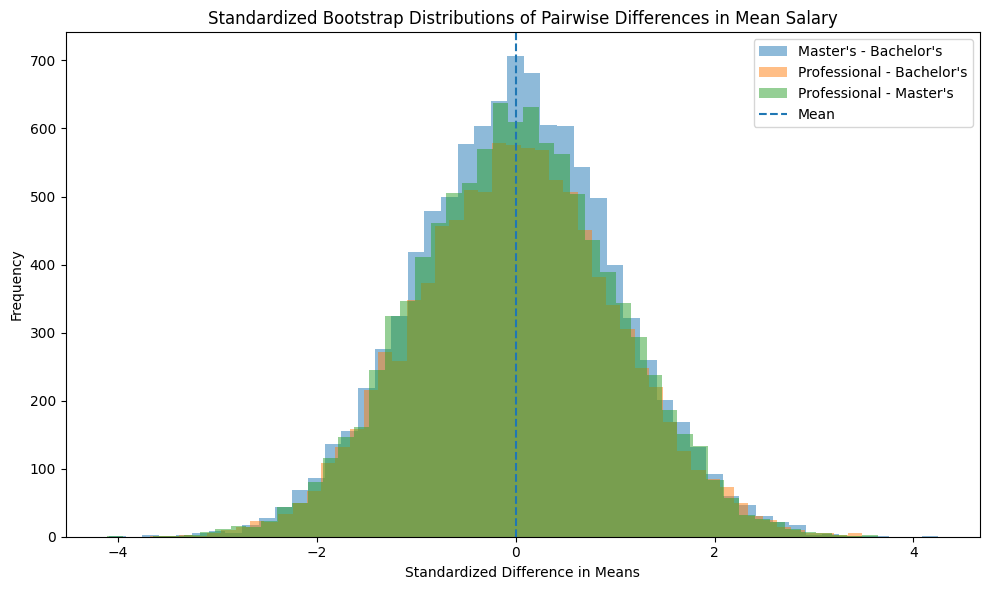

In [64]:
# Standardized pairwise bootstrap distributions

plt.figure(figsize=(10, 6))

plt.hist(
    std_diff_masters_bachelors,
    bins=50,
    alpha=0.5,
    label="Master's - Bachelor's"
)

plt.hist(
    std_diff_professional_bachelors,
    bins=50,
    alpha=0.5,
    label="Professional - Bachelor's"
)

plt.hist(
    std_diff_professional_masters,
    bins=50,
    alpha=0.5,
    label="Professional - Master's"
)

plt.axvline(0, linestyle='--', label='Mean')

plt.title('Standardized Bootstrap Distributions of Pairwise Differences in Mean Salary')
plt.xlabel('Standardized Difference in Means')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()

**3c.3 Interpretation:**  
The standardized pairwise bootstrap distributions are approximately bell-shaped and centered near zero, indicating that the resampled mean differences are distributed fairly symmetrically around their respective average differences.

## Question 3d: ANOVA with the Bootstrapped Data

In [65]:
# Bootstrap ANOVA

np.random.seed(42)

n_bootstrap = 10000
bootstrap_f_stats = np.empty(n_bootstrap)

for i in range(n_bootstrap):

    bachelors_sample = np.random.choice(
        bachelors_salary,
        size=len(bachelors_salary),
        replace=True
    )

    masters_sample = np.random.choice(
        masters_salary,
        size=len(masters_salary),
        replace=True
    )

    professional_sample = np.random.choice(
        professional_salary,
        size=len(professional_salary),
        replace=True
    )

    bootstrap_f_stats[i], _ = stats.f_oneway(
        bachelors_sample,
        masters_sample,
        professional_sample
    )

print("Mean bootstrap F-statistic:", bootstrap_f_stats.mean())
print("Original ANOVA F-statistic:", f_stat)

Mean bootstrap F-statistic: 33.49363697969536
Original ANOVA F-statistic: 32.17274765856014


In [66]:
# ANOVA degrees of freedom
k = 3

N = (
    len(bachelors_salary)
    + len(masters_salary)
    + len(professional_salary)
)

df_between = k - 1
df_within = N - k

# Critical F-value at alpha = 0.05
alpha = 0.05

f_critical = stats.f.ppf(
    1 - alpha,
    df_between,
    df_within
)

print("Critical F-value:", f_critical)

Critical F-value: 2.997904201230997


In [67]:
# Proportion of bootstrap ANOVAs that are significant
bootstrap_significant = np.mean(
    bootstrap_f_stats > f_critical
)

print(
    "Proportion of bootstrap ANOVAs significant:",
    bootstrap_significant
)

Proportion of bootstrap ANOVAs significant: 1.0


**3d Interpretation:**  
The original ANOVA in Question 3b produced an F-statistic of approximately 32.17 and a p-value far below 0.05, indicating a significant difference in mean salary among the three education groups. In the bootstrap analysis, 100% of the 10,000 resampled ANOVAs produced F-statistics above the critical value at the 0.05 significance level. Therefore, the bootstrap results support the same conclusion as the original ANOVA: at least one education group has a significantly different mean salary.